# UCS420 Lab Assignment 7 — NLP Text Preprocessing


In [28]:
ROLL_NO = 1024160028          # <-- your full roll number
NAME = "Saket Gatyan"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [29]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [30]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [31]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160028   Name: Saket Gatyan   Fingerprint: 5CAFD173   Tickets: 15

Ticket_ID                                                                          Ticket_Text
      T01 Python failed to open before the assignment deadline. The same problem occurs again.
      T02                                                 Python 3.12 was installed yesterday.
      T03                                      The VPN is showing an error. Please resolve it.
      T04                            The printer is running slowly. Is there another solution?
      T05                                           The VPN failed to open. Please resolve it.
      T06        I can't open the student portal after the latest update. It worked yesterday.
      T07                                    LMS stopped responding on my laptop. Please help.
      T08                                            The printer won't print; it isn't jammed.
      T09                                                    

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [32]:

def process_ticket(text):
  text = text.lower()

  sentences = sent_tokenize(text)  # sentences count Preprocessing

  tokens = word_tokenize(text) # spliting the words for each sentence

  punctuations_tokens = [
      t for t in tokens if all(ch in string.punctuation for ch in t)
  ]
  sw = set(stopwords.words("english"))

  actualstopwords = [t for t in tokens if t in sw]

  uniqtokens = set(tokens)

  final_tokens = [t for t in tokens if t not in punctuations_tokens and t not in sw]

  return pd.Series({
      "sentences":len(sentences),
      "tokens":len(tokens),
      "punctuations tokens":len(punctuations_tokens),
      "stopwords  ":len(actualstopwords),
      "unique tokens":len(uniqtokens),
      "final tokens": len(final_tokens),
  })

results = df['Ticket_Text'].apply(process_ticket)
print(results)
table =  pd.concat([df['Ticket_ID'],results],axis=1)
print(table)

    sentences  tokens  punctuations tokens  stopwords    unique tokens  \
0           2      15                    2            6             13   
1           1       6                    1            1              6   
2           2      11                    2            4             10   
3           2      11                    2            4             10   
4           2      10                    2            3              9   
5           2      16                    2            5             14   
6           2      10                    2            2              9   
7           1      11                    2            3             10   
8           1       7                    2            1              7   
9           2      15                    2            4             14   
10          2      10                    2            3              9   
11          2      12                    2            6             12   
12          2      15                 

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* These are tokens which are not a real word. They come from contractions in the original text which are meaningless for the language. Example : can't into ca & n't


In [33]:
# for checking the final tokens

def get_final_tokens(text):
  text = text.lower()
  sentences = sent_tokenize(text)

  tokens = word_tokenize(text)

  punctuations_tokens = [
      t for t in tokens if all(ch in string.punctuation for ch in t)
  ]
  sw = set(stopwords.words("english"))

  actualstopwords = [t for t in tokens if t in sw]

  uniqtokens = set(tokens)

  final_tokens = [t for t in tokens if t not in punctuations_tokens and t not in sw]
  return final_tokens

REALTOKENS = df['Ticket_Text'].apply(get_final_tokens)
print(REALTOKENS)

#printing only those who isnt the standard token.

for tokens in REALTOKENS:
  for i in tokens:
    if i in ["n't","'s","ca"]:
      print(tokens)




0     [python, failed, open, assignment, deadline, p...
1                  [python, 3.12, installed, yesterday]
2                [vpn, showing, error, please, resolve]
3         [printer, running, slowly, another, solution]
4                  [vpn, failed, open, please, resolve]
5     [ca, n't, open, student, portal, latest, updat...
6      [lms, stopped, responding, laptop, please, help]
7                [printer, wo, n't, print, n't, jammed]
8                           [ticket, 4521, still, open]
9     [student, portal, stopped, syncing, since, yes...
10          [matlab, stopped, syncing, please, resolve]
11                        [wifi, showing, error, check]
12    [matlab, failed, open, connected, campus, wi-f...
13    [reinstalled, server, latest, update, please, ...
14                             [tried, still, response]
Name: Ticket_Text, dtype: object
['ca', "n't", 'open', 'student', 'portal', 'latest', 'update', 'worked', 'yesterday']
['ca', "n't", 'open', 'student', 'portal'

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [34]:

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

def extract_patterns(text):
    return pd.Series({
        'long_words': re.findall(r'\b[A-Za-z]{6,}\b', text),
        'numbers': re.findall(r'\b\d+(?:\.\d+)*\b', text),
        'capitalized_words': re.findall(r'\b[A-Z][a-zA-Z]*\b', text),
        'vowel_words': re.findall(r'\b[AEIOUaeiou][A-Za-z]*\b', text)
    })

def clean_text(text):
    text = re.sub(
        r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b',
        '[EMAIL]', text
    )
    text = re.sub(
        r'(?:https?://|www\.)\S+',
        '[URL]', text, flags=re.IGNORECASE
    )
    text = re.sub(
        r'(?<!\w)(?:\+?\d[\d\s().-]{7,}\d)(?!\w)',
        '[PHONE]', text
    )
    return text

# Extract patterns from every raw ticket
results = df['Ticket_Text'].apply(extract_patterns)

# Add ticket IDs
results.insert(0, 'Ticket_ID', df['Ticket_ID'].values)

# Clean raw ticket text
results['cleaned_text'] = df['Ticket_Text'].apply(clean_text)

print(results.to_string(index=False))

# Testing on the TESTLINES data
i=0
for text in TEST_LINES:
  i=i+1
  print(i)
  print("long_words",re.findall(r'\b[A-Za-z]{6,}\b', text))
  print("numbers:", re.findall(r'\b\d+(?:\.\d+)*\b', text))
  print("capitalized_words:" ,re.findall(r'\b[A-Z][a-zA-Z]*\b', text))
  print("vowel_words:", re.findall(r'\b[AEIOUaeiou][A-Za-z]*\b', text))




Ticket_ID                                                      long_words numbers     capitalized_words                       vowel_words                                                                         cleaned_text
      T01 [Python, failed, before, assignment, deadline, problem, occurs]      []         [Python, The] [open, assignment, occurs, again] Python failed to open before the assignment deadline. The same problem occurs again.
      T02                                  [Python, installed, yesterday]  [3.12]              [Python]                       [installed]                                                 Python 3.12 was installed yesterday.
      T03                                      [showing, Please, resolve]      []    [The, VPN, Please]               [is, an, error, it]                                      The VPN is showing an error. Please resolve it.
      T04                   [printer, running, slowly, another, solution]      []             [The, Is]     

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [42]:
from nltk.tokenize import RegexpTokenizer
def my_tokenize(text):
  pattern = r"https?://\S+|www\.\S+|[\w.+-]+@[\w.+-]+\.[A-Za-z]{2,}|\+?\d[\d(). -]{7,}\d|\d+(?:\.\d+)+|[A-Za-z]+(?:['’][A-Za-z]+)+|[A-Za-z]+(?:-[A-Za-z]+)+|[A-Za-z]+|\d+|[^\w\s]"
  tokenizer = RegexpTokenizer(pattern)
  return tokenizer.tokenize(text)

for text in TEST_LINES:
  print("Comparing word_tokenize vs my_tokenize")
  my_text = word_tokenize(text)
  print("by word tokenize")
  print(my_text)
  print("by my_tokenize")
  print(my_tokenize(text))

Comparing word_tokenize vs my_tokenize
by word tokenize
['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
by my_tokenize
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
Comparing word_tokenize vs my_tokenize
by word tokenize
['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
by my_tokenize
['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
Comparing word_tokenize vs my_tokenize
by word tokenize
['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'work', '.']
by my_tokenize
['The', 'state-of-the-art', '

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* Each ticket is tokenized with email,phone no.s,hypened words etc as a whole token with the custom function whereas word_tokenize returns each word as token including stopwords and punctuation marks.  

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
from nltk.stem import PorterStemmer, LancasterStemmer
from nltk.stem import RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.tokenize import word_tokenize
import pandas as pd
import nltk

#nltk.download('averaged_perceptron_tagger_eng')
#nltk.download('wordnet')
#nltk.download('omw-1.4')

#Get all unique tokens from Ticket_Text
uni = set()

for i in df['Ticket_Text'].dropna():
    tokens = word_tokenize(i.lower())
    uni.update(tokens)

uni = sorted(uni)

print("Unique tokens:", uni)

#Initialize stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp = RegexpStemmer(r'ing$|ed$|s$', min=4)
lemmatizer = WordNetLemmatizer()

#Convert POS tags to WordNet POS
def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return 'a'
    elif tag.startswith('V'):
        return 'v'
    elif tag.startswith('N'):
        return 'n'
    elif tag.startswith('R'):
        return 'r'
    else:
        return 'n'

# Get POS tags
tagged_tokens = pos_tag(uni)

# Apply all four methods
rows = []

for word, tag in tagged_tokens:
    pos = get_wordnet_pos(tag)

    rows.append({
        'Word': word,
        'POS Tag': tag,
        'Porter': porter.stem(word),
        'Lancaster': lancaster.stem(word),
        'Regexp': regexp.stem(word),
        'Lemmatization': lemmatizer.lemmatize(word, pos=pos)
    })

results = pd.DataFrame(rows)

#show only words where outputs differ
methods = ['Porter', 'Lancaster', 'Regexp', 'Lemmatization']

different_words = results[
    results[methods].nunique(axis=1) > 1
]

print("Words where outputs differ:")
print(different_words.to_string(index=False))

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Unique tokens: ['!', '#', '.', '...', '3.12', '4521', ';', '?', 'after', 'again', 'an', 'another', 'assignment', 'before', 'ca', 'campus', 'can', 'changed', 'check', 'connected', 'deadline', 'do', 'error', 'failed', 'has', 'help', 'i', 'installed', 'is', 'it', 'jammed', 'know', 'laptop', 'latest', 'lms', 'matlab', 'my', "n't", 'no', 'occurs', 'on', 'open', 'please', 'portal', 'print', 'printer', 'problem', 'python', 'reinstalled', 'resolve', 'responding', 'response', 'running', 'same', 'server', 'showing', 'since', 'slowly', 'solution', 'still', 'stopped', 'student', 'syncing', 'the', 'there', 'this', 'ticket', 'to', 'tried', 'update', 'vpn', 'was', 'what', 'when', 'wi-fi', 'wifi', 'wo', 'worked', 'yesterday', 'you']

Words where outputs differ:
       Word POS Tag   Porter Lancaster     Regexp Lemmatization
      after      IN    after       aft      after         after
    another      DT    anoth     anoth    another       another
 assignment      NN   assign    assign assignment   

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*  Over-stemming: When a stemmer removes too much of a word, changing its meaning or producing an invalid stem.

Under-stemming: When a stemmer fails to reduce related words to their common stem.

Use your different_words table to select one example of each. For example:

Over-stemming: If Lancaster converts university to an incorrect or excessively shortened stem.

Under-stemming: If Porter produces different stems for two related words, such as connect and connected.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

['python', 'failed', 'to', 'open', 'before', 'the', 'assignment', 'deadline', '.', 'the', 'same', 'problem', 'occurs', 'again', '.', 'python', '3.12', 'was', 'installed', 'yesterday', '.', 'the', 'vpn', 'is', 'showing', 'an', 'error', '.', 'please', 'resolve', 'it', '.', 'the', 'printer', 'is', 'running', 'slowly', '.', 'is', 'there', 'another', 'solution', '?', 'the', 'vpn', 'failed', 'to', 'open', '.', 'please', 'resolve', 'it', '.', 'i', 'ca', "n't", 'open', 'the', 'student', 'portal', 'after', 'the', 'latest', 'update', '.', 'it', 'worked', 'yesterday', '.', 'lms', 'stopped', 'responding', 'on', 'my', 'laptop', '.', 'please', 'help', '.', 'the', 'printer', 'wo', "n't", 'print', ';', 'it', 'is', "n't", 'jammed', '.', 'ticket', '#', '4521', 'is', 'still', 'open', '.', 'student', 'portal', 'has', 'stopped', 'syncing', 'since', 'yesterday', '.', 'i', 'do', "n't", 'know', 'what', 'changed', '.', 'the', 'matlab', 'has', 'stopped', 'syncing', '.', 'please', 'resolve', 'it', '.', 'the', 'w

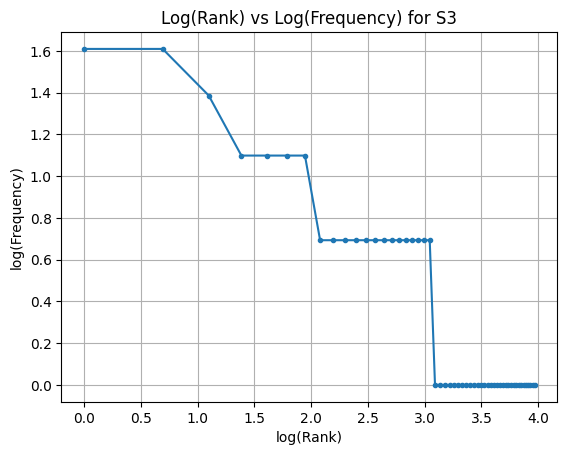


Top 5 bigrams in S1:
[(('.', 'the'), 6), (('.', 'please'), 5), (('failed', 'to'), 3), (('to', 'open'), 3), (('yesterday', '.'), 3)]

Top 5 bigrams in S3:
[(('failed', 'open'), 3), (('please', 'resolve'), 3), (('showing', 'error'), 2), (('open', 'student'), 2), (('student', 'portal'), 2)]


In [50]:
import string
import math
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import ngrams
from nltk.stem import PorterStemmer

# Getting S1 S2 S3 S4
S1 = []
for i in df['Ticket_Text'].dropna():
  tokens = (word_tokenize(i.lower()))
  S1.extend(tokens)

S2 = [w for w in S1 if w not in string.punctuation ]
stopwd = set(stopwords.words('english'))
S3 = [w for w in S2 if w not in stopwd]

print(S1)
print(S2)
print(S3)

porter = PorterStemmer()
S4 = [porter.stem(word) for word in S3]


# Compute tokens, unique tokens and TTR
def corpus_stats(name, tokens):
    total_tokens = len(tokens)
    unique_tokens = len(set(tokens))
    ttr = unique_tokens / total_tokens if total_tokens > 0 else 0

    print(f"\n{name}")
    print("Total tokens:", total_tokens)
    print("Unique tokens:", unique_tokens)
    print("TTR:", round(ttr, 4))


corpus_stats("S1 - All tokens", S1)
corpus_stats("S2 - No punctuation", S2)
corpus_stats("S3 - Final tokens", S3)
corpus_stats("S4 - Porter stemmed", S4)


#Print top 10 words of S1 and S3
print("\nTop 10 words in S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))


# log(rank) vs log(frequency)
freq = Counter(S3)
ranked_freq = sorted(freq.values(), reverse=True)

ranks = list(range(1, len(ranked_freq) + 1))

log_rank = [math.log(r) for r in ranks]
log_freq = [math.log(f) for f in ranked_freq]

plt.plot(log_rank, log_freq, marker='.')
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()



print("\nTop 5 bigrams in S1:")
bigrams_S1 = Counter(ngrams(S1, 2))
print(bigrams_S1.most_common(5))

print("\nTop 5 bigrams in S3:")
bigrams_S3 = Counter(ngrams(S3, 2))
print(bigrams_S3.most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR changes from S1 to S4 because preprocessing removes punctuation and stopwords, while Porter Stemming converts different forms of words into common stems. This changes the number of total and unique tokens. Generally, stemming reduces vocabulary diversity by combining related word forms, which can lower TTR
